# Learning module 12 — Observe the current UI before choosing an action

**Small milestone:** open a fresh session, capture the current native UI hierarchy and a screenshot, then close the session. Read the saved evidence afterward. We will not tap, type, scroll, or run the Interstellar assertions.

The two new automation calls are:

```python
source_xml = session_driver.page_source
screenshot_png = session_driver.get_screenshot_as_png()
```

`page_source` asks Appium for the current hierarchy. In this native XCUITest session it returns an XML representation of the accessibility hierarchy, not Flutter's Dart widget tree or the app's complete navigation graph. `get_screenshot_as_png()` returns actual screenshot bytes through Appium/XCUITest; the driver may use a Simulator fallback when its WDA screenshot path fails. Neither call requires an LLM. [WebDriver source/screenshot commands](https://appium.io/docs/en/latest/reference/api/webdriver/), [XCUITest screenshot implementation](https://github.com/appium/appium-xcuitest-driver/blob/master/lib/commands/screenshots.ts)

This is the **observe** part of our future observe → choose → execute → observe loop. Later an agent will use this evidence to choose an action. Here we collect and inspect the evidence ourselves.

**Prerequisites:** select the project `.venv` kernel and run this notebook's setup cells. The execution cell revalidates its target itself. Its old session is closed; do not reuse that driver. The code below reuses the same session lifecycle pattern, including the explicit reset policy, loopback server, and nested cleanup. Run serially on the selected Simulator. Existing dependency findings remain unresolved.

The cell rechecks the current Simulator and installed bundle immediately before starting. Evidence is saved in a new directory under ignored `server/.tools/observations/`, alongside a JSON manifest linking it to the actual session. Separate UTC start/end times make clear that XML and screenshot requests are sequential observations, not an atomic snapshot. Normal app activity may change the screen between them.


## This notebook

Part **12 — Capture native hierarchy and screenshot** of the learning sequence. [Notebook index](README.md).

Select the project's `.venv` Python kernel and run this notebook from top to bottom. Its Python setup is included locally; running another notebook in another kernel does not populate this one's variables or PATH. The supported working directories are the project root, `server/`, and `server/sample_scenarios/`.

**Execution scope:** Real session and read operations.

Saved lesson outputs and embedded screenshots are historical snapshots preserved during the split on November 3, 2026. Newly included setup cells have no saved outputs. Rerunning an executable scenario creates fresh local artifacts; these continue living in `server/.tools/`, not beside the notebooks.

### Setup for this notebook

These source-only prerequisite cells are repeated intentionally so the lesson is runnable in a fresh kernel. They configure local values/environment and inspect tool versions; they do not launch an Appium server, create a session, or tap/type in the app. The original lessons remain linked for explanation.


In [1]:
# Setup: Sample scenario input (lesson 01)
from pprint import pprint

scenario_text = (
    "In Movies, search for Interstellar, open the 2014 movie, "
    "and verify that its details show the title Interstellar "
    "and release year 2014."
)

scenario_input = {
    "instruction": scenario_text,
    "application_name": "Movies",
    "application_profile_ref": None,
    "requested_actions": [
        "search_for_movie",
        "open_matching_movie_details",
    ],
    "search_query": "Interstellar",
    "target_item_identity": {"title": "Interstellar", "release_year": 2014},
    "expected_title": "Interstellar",
    "expected_release_year": 2014,
    "title_matching_rule": "exact",  # Proposed comparison rule for this exercise.
}

pprint(scenario_input, sort_dicts=False)


{'instruction': 'In Movies, search for Interstellar, open the 2014 movie, and '
                'verify that its details show the title Interstellar and '
                'release year 2014.',
 'application_name': 'Movies',
 'application_profile_ref': None,
 'requested_actions': ['search_for_movie', 'open_matching_movie_details'],
 'search_query': 'Interstellar',
 'target_item_identity': {'title': 'Interstellar', 'release_year': 2014},
 'expected_title': 'Interstellar',
 'expected_release_year': 2014,
 'title_matching_rule': 'exact'}


In [2]:
# Setup: Recorded run profile (lesson 03)
from pprint import pprint

run_profile = {
    "id": "movies-ios-local",
    "platform": "ios",
    "execution_provider": "local",
    "app_bundle_id": "com.example.movies",
    "simulator_udid": "4F0707AE-45BC-464D-9099-6EE76C3740A9",
}

app_profiles = {run_profile["id"]: run_profile}
scenario_input["application_profile_ref"] = run_profile["id"]
selected_profile = app_profiles[scenario_input["application_profile_ref"]]

print("Scenario profile reference:", scenario_input["application_profile_ref"])
pprint(selected_profile, sort_dicts=False)


Scenario profile reference: movies-ios-local
{'id': 'movies-ios-local',
 'platform': 'ios',
 'execution_provider': 'local',
 'app_bundle_id': 'com.example.movies',
 'simulator_udid': '4F0707AE-45BC-464D-9099-6EE76C3740A9'}


In [3]:
# Setup: Local Node activation (lesson 05)
import os
from pathlib import Path
import shutil
import subprocess

notebook_cwd = Path.cwd().resolve()
server_candidates = (notebook_cwd, notebook_cwd / "server", *notebook_cwd.parents)
server_dir = next((candidate for candidate in server_candidates
                   if (candidate / ".node-version").is_file()
                   and (candidate / "package.json").is_file()
                   and (candidate / "sample_scenarios").is_dir()), None)
if server_dir is None:
    raise RuntimeError("Run from the project root, server, or sample_scenarios folder.")

node_version = (server_dir / ".node-version").read_text().strip()
node_bin = server_dir / ".tools" / f"node-v{node_version}-darwin-arm64" / "bin"
if not (node_bin / "node").is_file():
    raise FileNotFoundError(f"Project-local Node is missing: {node_bin}")

path_entries = [entry for entry in os.environ.get("PATH", "").split(os.pathsep)
                if entry != str(node_bin)]
os.environ["PATH"] = os.pathsep.join([str(node_bin), *path_entries])

print("Selected Node:", shutil.which("node"))
print("Node version:", subprocess.check_output(["node", "--version"], text=True, timeout=10).strip())
print("npm version:", subprocess.check_output(["npm", "--version"], text=True, timeout=10).strip())


Selected Node: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/node-v24.22.2-darwin-arm64/bin/node
Node version: v24.22.2
npm version: 11.19.1


In [4]:
# Setup: Local Appium activation (lesson 06)
import json
import os
import shutil
import subprocess

if "server_dir" not in globals() or "node_bin" not in globals():
    raise RuntimeError("Run the Node setup cell in this notebook first.")
if shutil.which("node") != str(node_bin / "node"):
    raise RuntimeError("Reactivate the project-local Node runtime first.")

appium_bin_dir = server_dir / "node_modules" / ".bin"
appium_executable = appium_bin_dir / "appium"
if not appium_executable.is_file():
    raise FileNotFoundError("The project-local Appium package is missing.")

os.environ["APPIUM_HOME"] = str(server_dir / ".tools" / "appium")
os.environ["npm_config_cache"] = str(server_dir / ".tools" / "npm-cache")
path_entries = [entry for entry in os.environ.get("PATH", "").split(os.pathsep)
                if entry != str(appium_bin_dir)]
os.environ["PATH"] = os.pathsep.join([str(appium_bin_dir), *path_entries])

expected_version = json.loads((server_dir / "package.json").read_text())["devDependencies"]["appium"]
actual_version = subprocess.check_output(
    [str(appium_executable), "--version"], cwd=server_dir, text=True, timeout=30
).strip()
if actual_version != expected_version:
    raise RuntimeError(f"Expected Appium {expected_version}, found {actual_version}.")

print("Selected Appium:", shutil.which("appium"))
print("Appium version:", actual_version)
print("Appium home:", os.environ["APPIUM_HOME"])


Selected Appium: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/node_modules/.bin/appium
Appium version: 3.9.0
Appium home: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/appium


dbug Appium Creating hash file directory: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/appium/node_modules/.cache/appium


In [5]:
# Setup: Local iOS options (lesson 09)
import json
from appium.options.ios import XCUITestOptions

if "selected_profile" not in globals():
    raise RuntimeError("Run the scenario/profile setup cells in this notebook first.")
if selected_profile.get("platform") != "ios":
    raise ValueError("This example requires an iOS run profile.")
for field in ["app_bundle_id", "simulator_udid"]:
    value = selected_profile.get(field)
    if not isinstance(value, str) or not value.strip():
        raise ValueError(f"The selected profile needs a nonempty {field}.")

ios_options = XCUITestOptions()
ios_options.udid = selected_profile["simulator_udid"]
ios_options.bundle_id = selected_profile["app_bundle_id"]
ios_options.no_reset = True
ios_options.full_reset = False

session_request = ios_options.to_w3c()
print(json.dumps(session_request, indent=2))


{
  "capabilities": {
    "firstMatch": [
      {}
    ],
    "alwaysMatch": {
      "appium:automationName": "XCUITest",
      "platformName": "iOS",
      "appium:udid": "4F0707AE-45BC-464D-9099-6EE76C3740A9",
      "appium:bundleId": "com.example.movies",
      "appium:noReset": true,
      "appium:fullReset": false
    }
  }
}


In [6]:
import json
import os
import shutil
import socket
import subprocess
import tempfile
import time
import urllib.error
import urllib.request
from appium import webdriver
from appium.options.ios import XCUITestOptions
from appium.webdriver.client_config import AppiumClientConfig
from selenium.webdriver.common.proxy import Proxy
from pathlib import Path
from datetime import datetime, timezone
import xml.etree.ElementTree as ET

observation = None

if not all(name in globals() for name in ("server_dir", "node_bin", "appium_executable", "ios_options")):
    raise RuntimeError("Run this notebook's setup cells first (and its definitions cell where present).")
if shutil.which("node") != str(node_bin / "node"):
    raise RuntimeError("Reactivate the project-local Node runtime.")
if os.environ.get("APPIUM_HOME") != str(server_dir / ".tools" / "appium"):
    raise RuntimeError("Reactivate the project-local Appium home.")
if ios_options.no_reset is not True or ios_options.full_reset is not False:
    raise ValueError("Rerun this notebook's profile/options setup cells to restore this exercise's explicit reset policy.")

# Revalidate the profile/options and installed target immediately before this run.
if "selected_profile" not in globals():
    raise RuntimeError("Run this notebook's profile setup cell first.")
if selected_profile.get("platform") != "ios" or selected_profile.get("execution_provider") != "local":
    raise ValueError("This example requires the local iOS profile.")
if ios_options.udid != selected_profile["simulator_udid"] or ios_options.bundle_id != selected_profile["app_bundle_id"]:
    raise ValueError("The profile/options differ; rerun this notebook's profile/options setup cells.")
devices = json.loads(subprocess.check_output(
    ["xcrun", "simctl", "list", "devices", "--json"], text=True, timeout=20,
))
targets = [d for entries in devices["devices"].values() for d in entries
           if d["udid"] == ios_options.udid]
if len(targets) != 1 or targets[0]["state"] != "Booted" or not targets[0].get("isAvailable"):
    raise RuntimeError("The selected Simulator must be available and booted.")
app_path = subprocess.check_output(
    ["xcrun", "simctl", "get_app_container", ios_options.udid, ios_options.bundle_id, "app"],
    text=True, timeout=20,
).strip()
if not Path(app_path).is_dir():
    raise RuntimeError("The installed Movies container could not be verified.")

host, port, wda_port = "127.0.0.1", 4723, 8100
with socket.socket() as probe:
    probe.bind((host, port))  # Leave an existing Appium server alone.

connection_options = XCUITestOptions().load_capabilities(ios_options.to_capabilities())
connection_options.set_capability("appium:wdaBindingIP", host)
connection_options.set_capability("appium:wdaLocalPort", wda_port)
server_url = f"http://{host}:{port}"
client_config = AppiumClientConfig(
    remote_server_addr=server_url, timeout=300,
    proxy=Proxy({"proxyType": "direct"}),
    init_args_for_pool_manager={"init_args_for_pool_manager": {"retries": 0}},
)
expected_version = json.loads((server_dir / "package.json").read_text())["devDependencies"]["appium"]
log_dir = server_dir / ".tools" / "logs"
log_dir.mkdir(parents=True, exist_ok=True)
with tempfile.NamedTemporaryFile(mode="w", prefix="observation-config-", suffix=".json",
                                 dir=log_dir, delete=False) as config_file:
    json.dump({"server": {}}, config_file)
status_opener = urllib.request.build_opener(urllib.request.ProxyHandler({}))
session_driver, session_process, session_result = None, None, None
with tempfile.NamedTemporaryFile(mode="w", prefix="observation-check-", suffix=".log",
                                 dir=log_dir, delete=False) as session_log:
    print("Server/session log:", session_log.name, flush=True)
    try:
        session_process = subprocess.Popen(
            [str(node_bin / "node"), str(appium_executable), "--config", config_file.name,
             "--address", host, "--port", str(port), "--log-no-colors", "--log-timestamp"],
            cwd=server_dir, env=os.environ.copy(), stdout=session_log, stderr=subprocess.STDOUT,
        )
        print("Owned Appium PID:", session_process.pid, flush=True)
        deadline = time.monotonic() + 30
        while time.monotonic() < deadline:
            if session_process.poll() is not None:
                raise RuntimeError(f"Appium exited early; inspect {session_log.name}")
            try:
                with status_opener.open(server_url + "/status", timeout=2) as response:
                    server_status = json.load(response)["value"]
                break
            except urllib.error.URLError:
                time.sleep(0.25)
        else:
            raise TimeoutError(f"Appium startup timed out; inspect {session_log.name}")
        if server_status.get("ready") is not True or server_status.get("build", {}).get("version") != expected_version:
            raise RuntimeError("Appium did not return the expected readiness/version.")
        if session_process.poll() is not None:
            raise RuntimeError("The owned server stopped before session creation.")
        print("Requesting XCUITest session; first WDA setup may take time...", flush=True)
        session_driver = webdriver.Remote(
            command_executor=server_url, options=connection_options, client_config=client_config,
        )
        if not session_driver.session_id:
            raise RuntimeError("The client did not receive a session ID.")
        session_result = {"session_id": session_driver.session_id,
                          "returned_capabilities": session_driver.capabilities}
        observation_root = server_dir / ".tools" / "observations"
        observation_root.mkdir(parents=True, exist_ok=True)
        evidence_dir = Path(tempfile.mkdtemp(prefix="ui-", dir=observation_root))
        manifest_path = evidence_dir / "manifest.json"
        observation = {
            "capture_status": "incomplete", "session_id": session_driver.session_id,
            "returned_target": {key: session_driver.capabilities.get(key)
                                for key in ("platformName", "platformVersion", "udid", "bundleId")},
            "server_log": session_log.name, "captures": {},
        }
        try:
            source_started_at = datetime.now(timezone.utc).isoformat()
            source_xml = session_driver.page_source
            source_completed_at = datetime.now(timezone.utc).isoformat()
            source_path = evidence_dir / "hierarchy.xml"
            source_path.write_text(source_xml, encoding="utf-8")
            observation["captures"]["hierarchy"] = {
                "path": str(source_path), "started_at": source_started_at,
                "completed_at": source_completed_at,
            }
            ET.fromstring(source_xml)  # Keep raw evidence even if XML validation fails.
            screenshot_started_at = datetime.now(timezone.utc).isoformat()
            screenshot_png = session_driver.get_screenshot_as_png()
            screenshot_completed_at = datetime.now(timezone.utc).isoformat()
            if not screenshot_png.startswith(b"\x89PNG\r\n\x1a\n"):
                raise ValueError("The screenshot response did not contain a PNG image.")
            screenshot_path = evidence_dir / "screen.png"
            screenshot_path.write_bytes(screenshot_png)
            observation["captures"]["screenshot"] = {
                "path": str(screenshot_path), "started_at": screenshot_started_at,
                "completed_at": screenshot_completed_at,
            }
            observation["capture_status"] = "complete"
        except Exception as error:
            observation["capture_error"] = {"type": type(error).__name__, "message": str(error)}
            raise
        finally:
            manifest_path.write_text(json.dumps(observation, indent=2), encoding="utf-8")
            print("Observation manifest:", manifest_path, flush=True)
        print(json.dumps(observation, indent=2), flush=True)
    finally:
        try:
            if session_driver is not None:
                client_config.timeout = 20  # Bound cleanup requests separately from startup.
                session_driver.quit()
                print("Automation session closed.", flush=True)
        finally:
            if session_process is not None:
                if session_process.poll() is None:
                    session_process.terminate()
                    try:
                        session_process.wait(timeout=20)
                    except subprocess.TimeoutExpired:
                        session_process.kill()
                        session_process.wait(timeout=5)
                print("Owned Appium process stopped:", session_process.poll() is not None, flush=True)


Server/session log: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/logs/observation-check-k7b8cuz8.log
Owned Appium PID: 6142
Requesting XCUITest session; first WDA setup may take time...
Observation manifest: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/observations/ui-pgcg44jm/manifest.json
{
  "capture_status": "complete",
  "session_id": "0aa907bc-706b-4c01-ba19-8e9b5f916232",
  "returned_target": {
    "platformName": "iOS",
    "platformVersion": "27.0",
    "udid": "4F0707AE-45BC-464D-9099-6EE76C3740A9",
    "bundleId": "com.example.movies"
  },
  "server_log": "/Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/logs/observation-check-k7b8cuz8.log",
  "captures": {
    "hierarchy": {
      "path": "/Users/tarunkhurana/Engineeri

### Inspect the saved hierarchy and screenshot after cleanup

The next cell only reads the saved files; it does not contact Appium. It prints a small sample of named, visible elements and displays the PNG. The complete XML stays available even when the preview is short.

| XML attribute | How to read it |
| --- | --- |
| `type` | Native XCTest element type, such as button or text field. |
| `name` | The accessibility identifier if available, otherwise the label; it is not automatically a Flutter semantics ID. |
| `label` | The accessibility label exposed by the element. |
| `value` | An element-dependent value, when present. |
| `enabled`, `visible` | Snapshot attribute strings; compare explicitly with `"true"`. Python treats even the nonempty string `"false"` as truthy. |

A named, visible, enabled node is not proof that it is uniquely identifiable or tappable. A later action will need a fresh observation and a verified locator. Flutter semantics merging/exclusion can also affect the native elements that appear. Missing controls are evidence to investigate, not permission to invent identifiers. [Native attributes](https://appium.github.io/appium-xcuitest-driver/latest/reference/element-attributes/)


Saved native nodes: 65
Element types: {'XCUIElementTypeApplication': 1, 'XCUIElementTypeWindow': 2, 'XCUIElementTypeOther': 44, 'XCUIElementTypeButton': 10, 'XCUIElementTypeScrollView': 1, 'XCUIElementTypeStaticText': 6, 'XCUIElementTypeSwitch': 1}
Sample only; the complete hierarchy is saved in: /Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/observations/ui-pgcg44jm/hierarchy.xml
[
  {
    "type": "XCUIElementTypeButton",
    "name": "movies.search.movie.157336.back",
    "label": "Back",
    "value": "",
    "enabled": "true",
    "visible": "true"
  },
  {
    "type": "XCUIElementTypeSwitch",
    "name": "movies.search.movie.157336.favorite",
    "label": "",
    "value": "0",
    "enabled": "true",
    "visible": "true"
  },
  {
    "type": "XCUIElementTypeButton",
    "name": "Favorite",
    "label": "Favorite",
    "value": "",
    "enabled": "true",
    "visible": "true"
  },
  {
    "type": "X

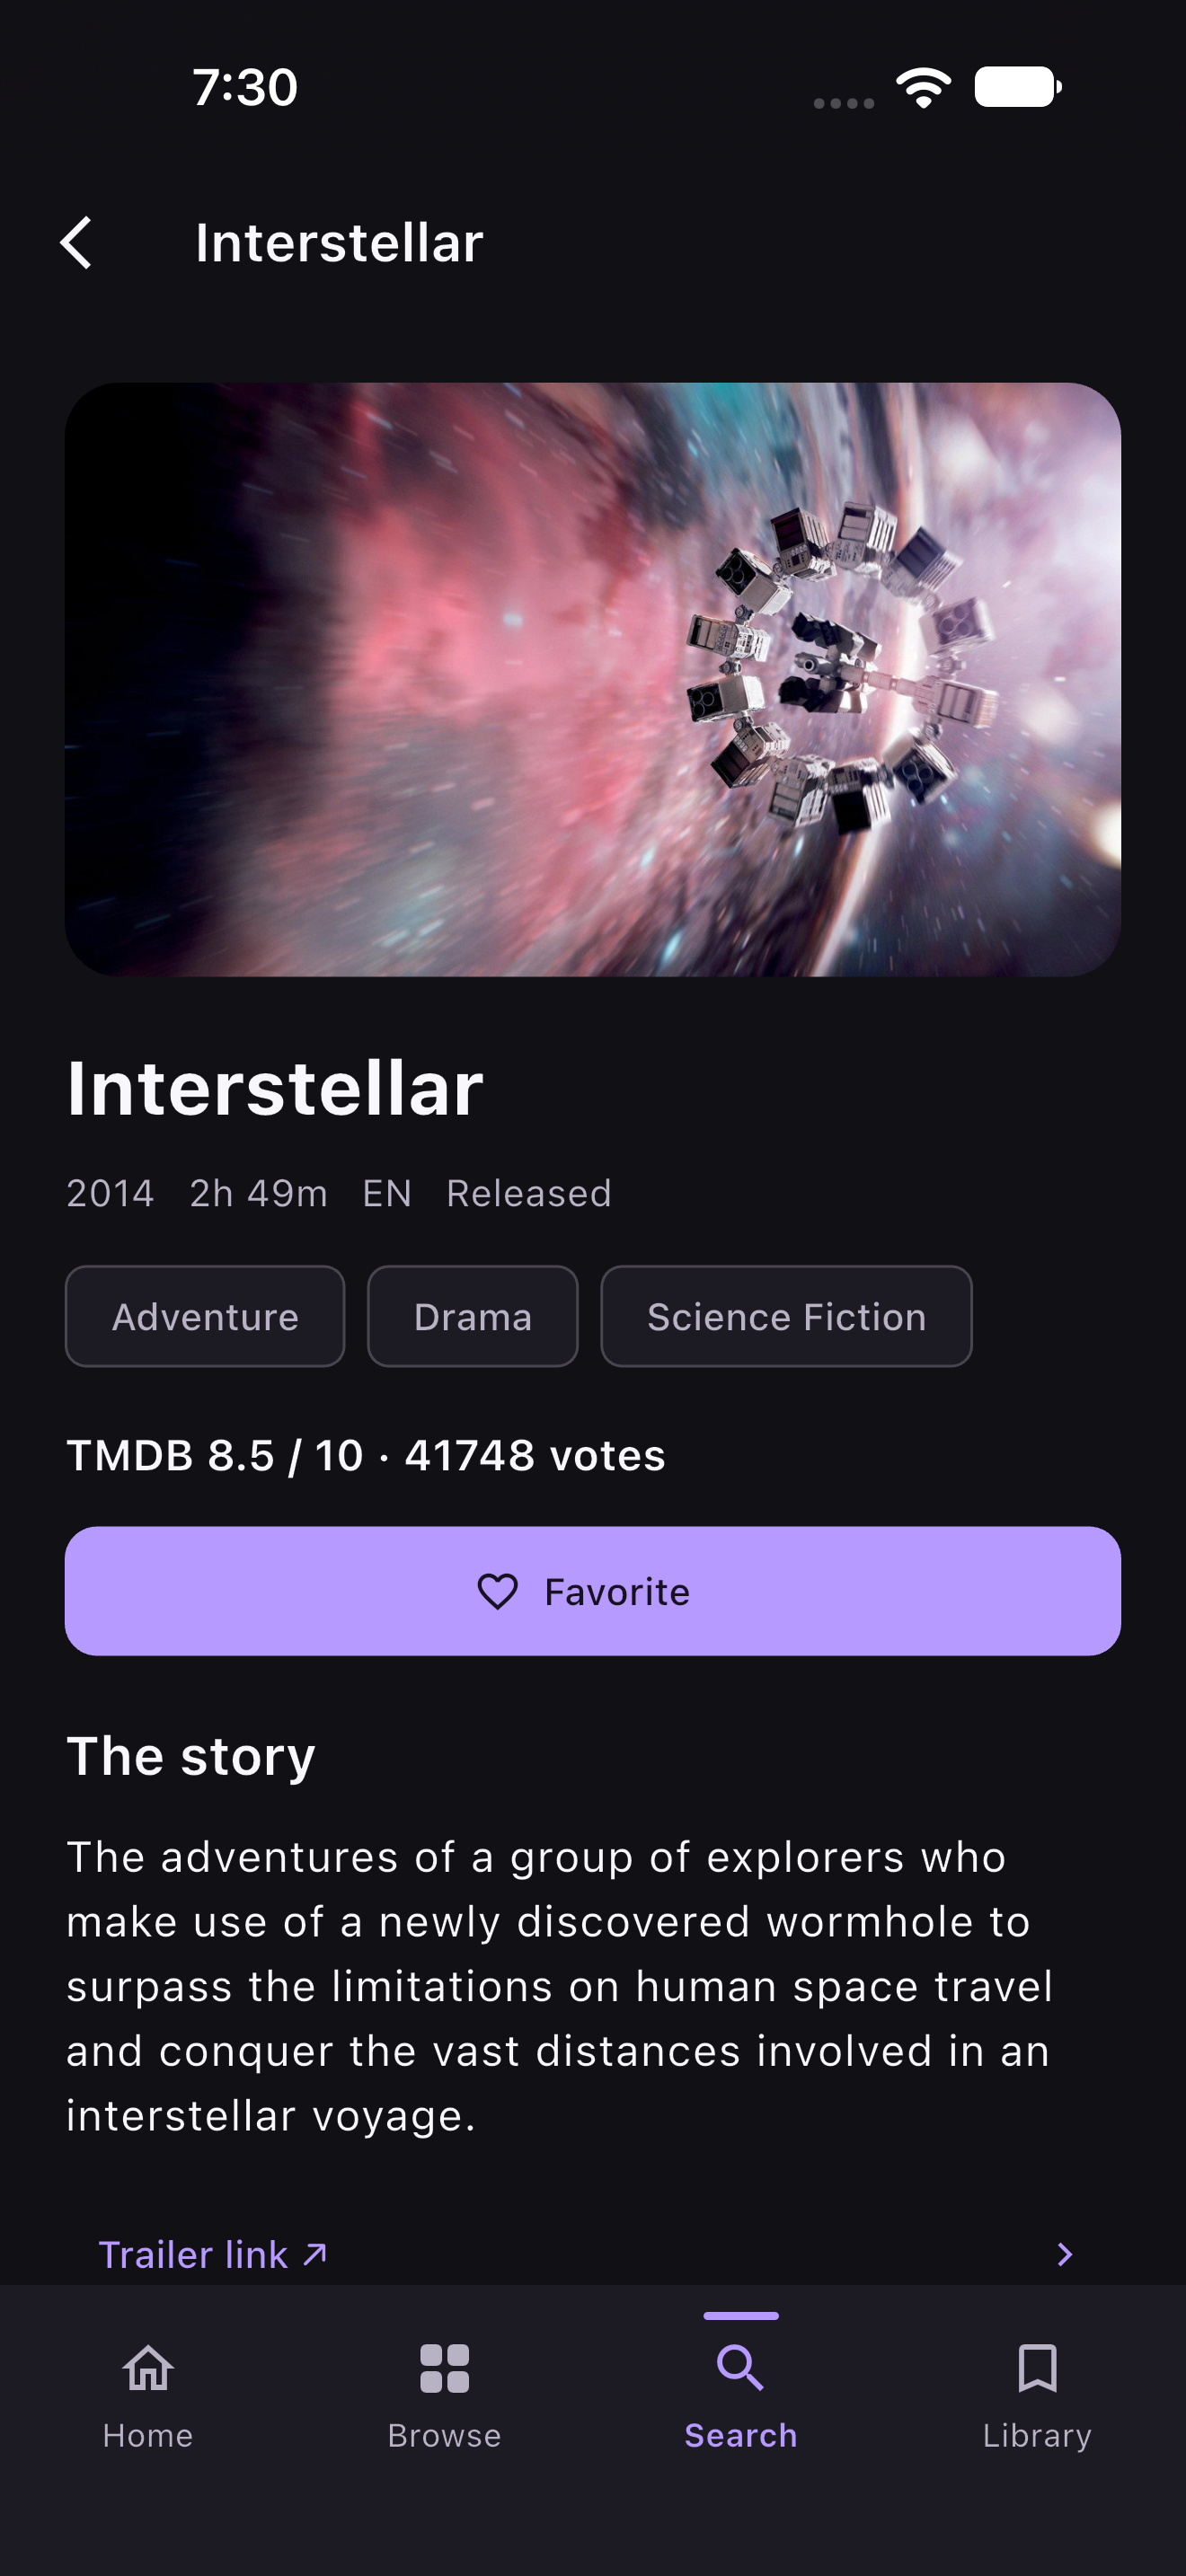

In [7]:
from collections import Counter
import json
from pathlib import Path
import xml.etree.ElementTree as ET
from IPython.display import Image, display

if not isinstance(globals().get("observation"), dict) or observation.get("capture_status") != "complete":
    raise RuntimeError("Run the observation cell successfully before previewing evidence.")
captures = observation["captures"]
xml_root = ET.parse(captures["hierarchy"]["path"]).getroot()
nodes = [node for node in xml_root.iter() if node.tag.startswith("XCUIElementType")]
named_visible = [node for node in nodes if node.get("visible") == "true"
                 and (node.get("name") or node.get("label"))]
controls = [node for node in named_visible if node.get("type", node.tag) in {
    "XCUIElementTypeButton", "XCUIElementTypeTextField", "XCUIElementTypeSearchField",
    "XCUIElementTypeSecureTextField", "XCUIElementTypeSwitch",
}]
preview_nodes = (controls or named_visible)[:20]
preview_rows = [{key: node.get(key, "")[:140]
                 for key in ("type", "name", "label", "value", "enabled", "visible")}
                for node in preview_nodes]
print("Saved native nodes:", len(nodes))
print("Element types:", dict(Counter(node.get("type", node.tag) for node in nodes)))
print("Sample only; the complete hierarchy is saved in:", captures["hierarchy"]["path"])
print(json.dumps(preview_rows, indent=2))
print("Screenshot:", captures["screenshot"]["path"])
display(Image(filename=captures["screenshot"]["path"], width=360))


### Read the observation, then pause

Compare the visible screenshot with the named nodes in the XML. The hierarchy exposes machine-readable structure; the screenshot provides visual context. Neither is a full map of routes hidden behind navigation, a selector to reuse forever, or evidence that the Interstellar assertions passed.

The manifest's `capture_status: complete` means **both observations were saved**, not that the business scenario passed. An incomplete run retains any saved evidence and records the capture error; keep that separate from an application assertion failure. Session deletion and server shutdown are reported separately in the cell output. A capture can complete even if cleanup later fails.

These are real observations of the preserved current app state. We did not substitute fixture UI, navigate to a predetermined screen, or prove that a fresh backend request succeeded. The native hierarchy is also different from Flutter widget information that an optional Dart MCP connection could provide.

The observations and preview remain readable after the session closes. We retain no usable live driver here; WDA or Movies may remain running for reuse, as in module 11.

**Pause here:** the next small step will be choosing one control from fresh evidence, verifying that a locator uniquely identifies it, and performing a single deliberate navigation action. We will not yet run the entire English scenario or introduce the multi-agent graph.


**Recorded execution:** `2026-11-03T03:35:49.957729+00:00` (UTC). Appium returned a native hierarchy with **54 nodes** and a **1320 × 2868 PNG**. The screenshot shows Browse with Upcoming selected; the notebook preview comes from the saved evidence. The local log confirms successful source/screenshot requests, session deletion, and Appium exit code `0`.

Some actual native attributes observed in this capture:

| Native type | `name` | `label` |
| --- | --- | --- |
| Button | `movies.shell.tab.search` | Search |
| Button | `movies.browse.results.movie.693134.open` | Open Dune: Part Two |
| Switch | `movies.browse.results.movie.693134.favorite` | Favorite Dune: Part Two |

These examples show why we inspect both type and name/label. The heart control appears as a native switch. `movies.shell.tab.search` is an observed candidate for the next learning step; we have not performed a live locator uniqueness check or tapped it.

Saved manifest: `/Users/tarunkhurana/Engineering/projects/tarunkhurana2015/ai-certification-gen-academy/week3-project-automated-testing/server/.tools/observations/ui-555ra7us/manifest.json`. The XML and PNG are alongside it; all are ignored local artifacts. The screenshot is also embedded in the preview output above.


[Index](README.md) · [Previous lesson](11_ios_session.ipynb) · [Next lesson](13_search_navigation.ipynb)